# Evaluation results

Reads what `evaluate.py` wrote to `results/` (`<tag>_metrics.json` and `<tag>_preds.jsonl` per run)
and compares the runs: output validity, per-field accuracy, per-example errors, and labels the model
invented. Every chart has a table with the exact numbers next to it; with n=12 test rows, one row is
about 8 percentage points.

In [1]:
import json
import pathlib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from common import FIELDS, load_jsonl, load_schema, schema_valid, short_prompt, fewshot_prompt, pick_shots

RESULTS_DIR = pathlib.Path("results")
MODE_ORDER = ["base_zeroshot", "base_fewshot", "finetuned"]
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

# Light chart theme: hairline grid, recessive axes, ink colors for all text
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.max_colwidth", 80)

## Load results

In [2]:
schema = load_schema()
allowed = {"primary_category": set(schema["primary_category"]),
           "specific_issue": {i for issues in schema["specific_issue"].values() for i in issues},
           **{f: set(schema[f]) for f in ("situation", "suggested_action", "urgency")}}


def is_invented(field, value):
    """A predicted value that isn't an allowed label anywhere in the schema (missing values are NaN)."""
    return isinstance(value, str) and value not in allowed[field]


metrics, rows = {}, []
for p in RESULTS_DIR.glob("*_metrics.json"):
    tag = p.name.removesuffix("_metrics.json")
    metrics[tag] = json.loads(p.read_text(encoding="utf-8"))
    for r in load_jsonl(RESULTS_DIR / f"{tag}_preds.jsonl"):
        pred = r["pred"] or {}
        row = {"run": tag, "id": r["id"], "complaint": r["complaint"], "raw_output": r["raw_output"],
               "parsed": r["pred"] is not None, "schema_valid": schema_valid(r["pred"], schema)}
        for f in FIELDS:
            row[f"gold_{f}"], row[f"pred_{f}"] = r["gold"][f], pred.get(f)
        rows.append(row)

# Fixed run order (zero-shot, few-shot, then fine-tuned adapters) and a fixed color per run
runs = sorted(metrics, key=lambda t: (MODE_ORDER.index(metrics[t]["mode"]), t))
COLORS = {t: PALETTE[i] for i, t in enumerate(runs)}
preds = pd.DataFrame(rows)
preds["run"] = pd.Categorical(preds["run"], categories=runs, ordered=True)
preds = preds.sort_values(["run", "id"]).reset_index(drop=True)
n = metrics[runs[0]]["n"]
print(f"{len(runs)} runs, {n} test rows each: {runs}")

3 runs, 12 test rows each: ['base_zeroshot', 'base_fewshot', 'finetuned_seed42']


## Prompts

The exact text each mode sends to the model, shown for the first test complaint and rebuilt with the same
`common.py` helpers `evaluate.py` uses. Zero-shot and fine-tuned send the same short prompt; the fine-tuned
run differs only by the LoRA adapter. The model's answer is generated right after the last line.

In [3]:
train = load_jsonl("train.jsonl")
complaint = load_jsonl("test.jsonl")[0]["complaint"]
k = next((m["k_shots"] for m in metrics.values() if m["mode"] == "base_fewshot"), 8)
prompts = {"base_zeroshot": short_prompt(complaint),
           "base_fewshot": fewshot_prompt(complaint, schema, pick_shots(train, k)),
           "finetuned": short_prompt(complaint)}
for mode, prompt in prompts.items():
    print(f"{'=' * 25} {mode} {'=' * 25}")
    print(prompt + "<model output starts here>")
    print()

========================= base_zeroshot =========================
Hearing aid patient complaint:
When we went to the diner on Sunday, the clatter of plates and the background chatter was absolutely deafening.

Structured JSON:
<model output starts here>

========================= base_fewshot =========================
Classify a hearing aid patient's complaint into a one-line JSON object with exactly these keys: primary_category, specific_issue, situation, suggested_action, urgency. Use only the allowed values below.

primary_category (the single problem the patient emphasizes most):
  - sound_quality: How sound itself is perceived (loudness, tone, feedback, distortion, own voice).
  - speech_understanding: Difficulty understanding speech in a given setting.
  - connectivity: Bluetooth, phone app, and streaming or accessory problems.
  - discomfort: Physical comfort and fit in or on the ear.
  - battery_charging: Battery life, charging, and charger problems.
  - performance_practicalit

## Overview

In [4]:
overview = pd.DataFrame({
    t: {"valid JSON": m["valid_json"], "schema-valid": m["schema_valid"],
        "all 5 fields exact": m["exact_match_all_fields"],
        **{f: m["fields"][f]["correct"] for f in FIELDS}}
    for t, m in metrics.items()}).T.loc[runs]
display((overview / n).style.format("{:.0%}").set_caption(f"Share of {n} test rows"))
display(overview.astype(str) + f"/{n}")

,valid JSON,schema-valid,all 5 fields exact,primary_category,specific_issue,situation,suggested_action,urgency
base_zeroshot,0%,0%,0%,0%,0%,0%,0%,0%
base_fewshot,100%,92%,33%,83%,50%,100%,75%,92%
finetuned_seed42,100%,50%,42%,75%,58%,92%,92%,100%


,valid JSON,schema-valid,all 5 fields exact,primary_category,specific_issue,situation,suggested_action,urgency
base_zeroshot,0/12,0/12,0/12,0/12,0/12,0/12,0/12,0/12
base_fewshot,12/12,11/12,4/12,10/12,6/12,12/12,9/12,11/12
finetuned_seed42,12/12,6/12,5/12,9/12,7/12,11/12,11/12,12/12


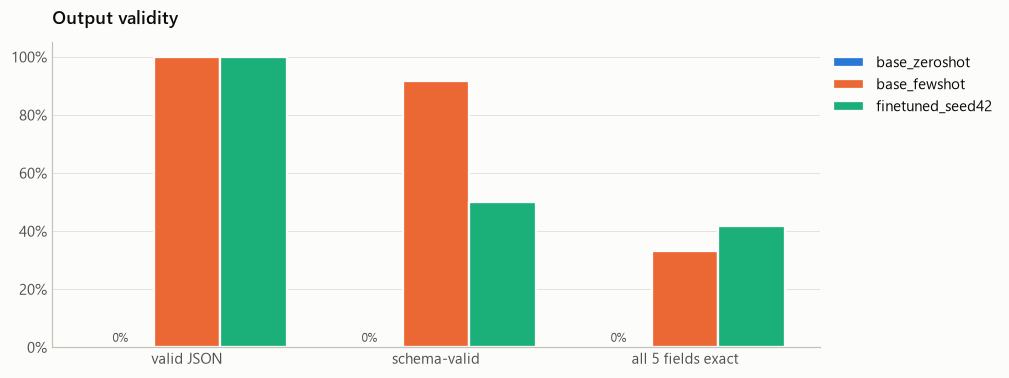

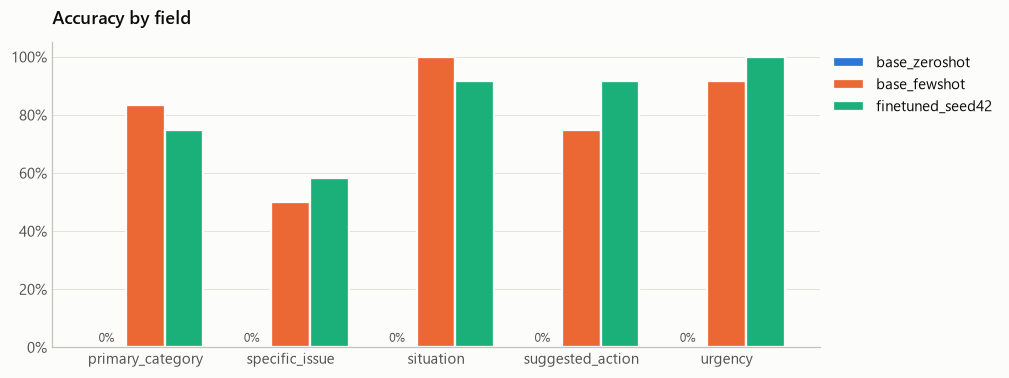

In [5]:
def grouped_bars(table, title, ax):
    """One group per column of `table`, one bar per run (row), colored by run."""
    k, width = len(table), 0.8 / len(table)
    x = range(len(table.columns))
    for i, (run, vals) in enumerate(table.iterrows()):
        ax.bar([xi + (i - (k - 1) / 2) * width for xi in x], vals.values / n, width,
               color=COLORS[run], edgecolor=SURFACE, linewidth=1.5, label=run)
        for xi, v in zip(x, vals.values):
            if v == 0:  # a zero-height bar is invisible, so mark it at the baseline
                ax.text(xi + (i - (k - 1) / 2) * width, 0.01, "0%", ha="center", va="bottom",
                        fontsize=8, color=INK_2)
    ax.set_xticks(list(x), table.columns)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

fig, ax = plt.subplots(figsize=(9, 3.6))
grouped_bars(overview[["valid JSON", "schema-valid", "all 5 fields exact"]], "Output validity", ax)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
grouped_bars(overview[FIELDS], "Accuracy by field", ax)
plt.show()

### Seen vs unseen labels

A test row's label is *unseen* if it never appears in `train.jsonl`. The fine-tuned model only sees the
short prompt, so it can only produce an unseen label by guessing its name.

In [6]:
seen = pd.DataFrame([
    {"run": t, "field": f,
     "seen": f"{d['seen_label_correct']}/{d['seen_label_n']}",
     "unseen": f"{d['unseen_label_correct']}/{d['unseen_label_n']}" if d["unseen_label_n"] else "–"}
    for t in runs for f, d in metrics[t]["fields"].items()])
(seen.pivot(index="field", columns="run", values=["seen", "unseen"])
 .reindex(index=FIELDS, columns=pd.MultiIndex.from_product([["seen", "unseen"], runs])))

seen                                      unseen  \
                 base_zeroshot base_fewshot finetuned_seed42 base_zeroshot   
field                                                                        
primary_category          0/12        10/12             9/12             –   
specific_issue            0/12         6/12             7/12             –   
situation                 0/12        12/12            11/12             –   
suggested_action          0/12         9/12            11/12             –   
urgency                   0/12        11/12            12/12             –   

                                                
                 base_fewshot finetuned_seed42  
field                                           
primary_category            –                –  
specific_issue              –                –  
situation                   –                –  
suggested_action            –                –  
urgency                     –                –

### Cost per run

In [7]:
pd.DataFrame({t: {"avg prompt tokens": m["avg_prompt_tokens"],
                  "avg seconds / example": m["avg_seconds_per_example"],
                  "few-shot examples": m["k_shots"]} for t, m in metrics.items()}).T.loc[runs]

,avg prompt tokens,avg seconds / example,few-shot examples
base_zeroshot,30.4,4.95,0.0
base_fewshot,1990.4,4.19,8.0
finetuned_seed42,30.4,7.41,0.0


## Per-example results

Each cell is one field of one test row. **Correct** = matches gold; **wrong label** = a valid label that
doesn't match gold; **invented** = a value that isn't in the schema at all; **no prediction** = no
parseable JSON, or the JSON lacks that field.

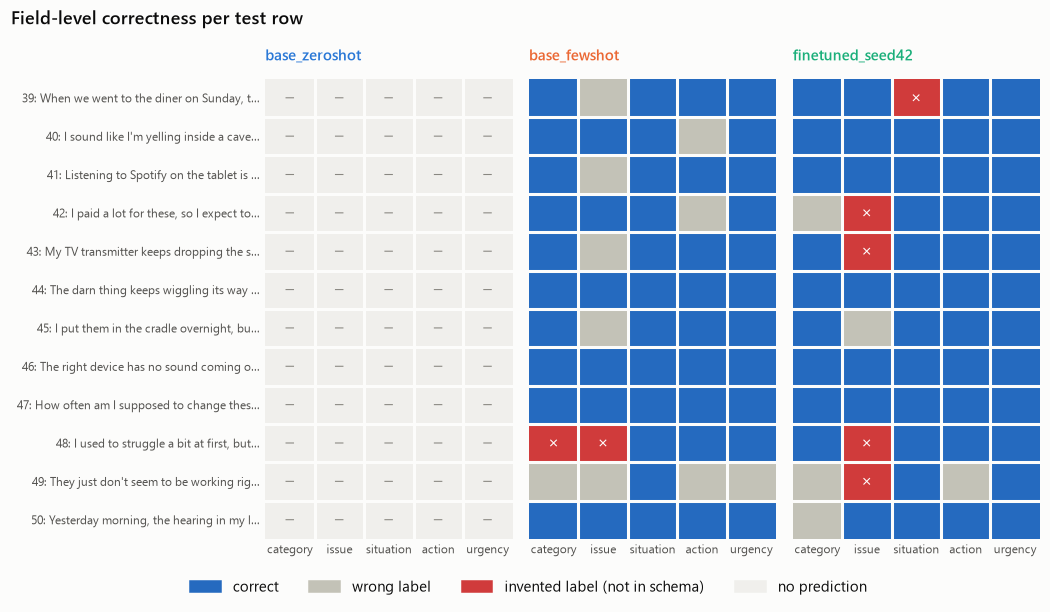

In [8]:
SHORT = {"primary_category": "category", "specific_issue": "issue", "situation": "situation",
         "suggested_action": "action", "urgency": "urgency"}


def cell_state(row, f):
    p = row[f"pred_{f}"]
    if p == row[f"gold_{f}"]:
        return 0  # correct
    if not isinstance(p, str):
        return 3  # no prediction
    return 2 if is_invented(f, p) else 1  # invented / wrong label

STATE_COLORS = ["#256abf", "#c3c2b7", "#d03b3b", "#f0efec"]
STATE_NAMES = ["correct", "wrong label", "invented label (not in schema)", "no prediction"]
STATE_GLYPHS = [("", None), ("", None), ("×", "#ffffff"), ("–", MUTED)]

labels = (preds[preds["run"] == runs[0]]
          .apply(lambda r: f"{r['id']}: {r['complaint'][:38]}…", axis=1).tolist())
fig, axes = plt.subplots(1, len(runs), figsize=(3 + 2.2 * len(runs), 0.32 * n + 1.6), sharey=True)
for ax, run in zip(axes, runs):
    sub = preds[preds["run"] == run]
    grid = [[cell_state(r, f) for f in FIELDS] for _, r in sub.iterrows()]
    ax.imshow(grid, cmap=ListedColormap(STATE_COLORS), vmin=0, vmax=3, aspect="auto")
    for y, line in enumerate(grid):
        for x, s in enumerate(line):
            glyph, color = STATE_GLYPHS[s]
            if glyph:
                ax.text(x, y, glyph, ha="center", va="center", color=color, fontsize=11)
    ax.set_xticks(range(len(FIELDS)), [SHORT[f] for f in FIELDS], fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.set_xticks([x - 0.5 for x in range(1, len(FIELDS))], minor=True)
    ax.set_yticks([y - 0.5 for y in range(1, len(labels))], minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(run, fontsize=10, color=COLORS[run])
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(STATE_COLORS, STATE_NAMES)],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Field-level correctness per test row", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [9]:
per_row = (preds.assign(fields_correct=[sum(r[f"pred_{f}"] == r[f"gold_{f}"] for f in FIELDS)
                                         for _, r in preds.iterrows()])
           .pivot(index="id", columns="run", values="fields_correct"))
per_row.insert(0, "complaint", preds.drop_duplicates("id").set_index("id")["complaint"].str[:60])
per_row

run,complaint,base_zeroshot,base_fewshot,finetuned_seed42
id,,,,
39,"When we went to the diner on Sunday, the clatter of plates a",0,4,4
40,"I sound like I'm yelling inside a cave whenever I speak, and",0,4,5
41,"Listening to Spotify on the tablet is wonderful, but the new",0,4,5
42,"I paid a lot for these, so I expect to hear every single wor",0,4,3
43,My TV transmitter keeps dropping the signal during my favori,0,4,4
44,The darn thing keeps wiggling its way out of my ear every ti,0,5,5
45,"I put them in the cradle overnight, but the light stays yell",0,4,4
46,The right device has no sound coming out whatsoever. I've tr,0,5,5
47,How often am I supposed to change these little white filters,0,5,5


## Errors

In [10]:
errors = pd.DataFrame([
    {"run": r["run"], "id": r["id"], "field": f, "gold": r[f"gold_{f}"], "pred": r[f"pred_{f}"],
     "invented": is_invented(f, r[f"pred_{f}"])}
    for _, r in preds[preds["parsed"]].iterrows() for f in FIELDS if r[f"pred_{f}"] != r[f"gold_{f}"]])
unparsed = preds[~preds["parsed"]].groupby("run", observed=True).size()
if len(unparsed):
    print("Rows with no parseable JSON (left out of the error table):", unparsed.to_dict())
errors.set_index(["run", "id"])

Rows with no parseable JSON (left out of the error table): {'base_zeroshot': 11}


field                          gold  \
run              id                                                   
base_zeroshot    39  primary_category                 sound_quality   
                 39    specific_issue     background_noise_annoying   
                 39         situation     noisy_restaurant_or_group   
                 39  suggested_action            adjust_programming   
                 39           urgency                       routine   
base_fewshot     39    specific_issue     background_noise_annoying   
                 40  suggested_action       physical_fit_adjustment   
                 41    specific_issue                   tv_or_media   
                 42  suggested_action  user_education_or_counseling   
                 43    specific_issue            other_connectivity   
                 45    specific_issue              charging_failure   
                 48  primary_category                         other   
                 48    specific_issue    positive_feedback_no_issue   
                 49  primary_category                         other   
                 49    specific_issue  unclear_or_insufficient_info   
                 49  suggested_action      request_more_information   
                 49           urgency                       routine   
finetuned_seed42 39         situation     noisy_restaurant_or_group   
                 42  primary_category          speech_understanding   
                 42    specific_issue               speech_in_noise   
                 43    specific_issue            other_connectivity   
                 45    specific_issue              charging_failure   
                 48    specific_issue    positive_feedback_no_issue   
                 49  primary_category                         other   
                 49    specific_issue  unclear_or_insufficient_info   
                 49  suggested_action      request_more_information   
                 50  primary_category                         other   

                                               pred  invented  
run              id                                            
base_zeroshot    39                             NaN     False  
                 39                             NaN     False  
                 39                             NaN     False  
                 39                             NaN     False  
                 39                             NaN     False  
base_fewshot     39                        too_loud     False  
                 40              adjust_programming     False  
                 41                 speech_in_quiet     False  
                 42              adjust_programming     False  
                 43         streaming_audio_quality     False  
                 45             unexpected_shutdown     False  
                 48      positive_feedback_no_issue      True  
                 48                      not_stated      True  
                 49        performance_practicality     False  
                 49              device_not_working     False  
                 49        check_hardware_or_repair     False  
                 49                            soon     False  
finetuned_seed42 39             restaurant_or_group      True  
                 42        performance_practicality     False  
                 42                   cost_or_value      True  
                 43                 tv_audio_cutout      True  
                 45                   charger_issue     False  
                 48                 no_issue_stated      True  
                 49        performance_practicality     False  
                 49  other_performance_practicality      True  
                 49         physical_fit_adjustment     False  
                 50        performance_practicality     False

### Invented labels

In [11]:
inv = errors[errors["invented"]]
if inv.empty:
    print("No invented labels.")
else:
    display(inv.groupby(["run", "field", "pred"], observed=True).size().rename("count").to_frame())

count
run              field            pred                                 
base_fewshot     primary_category positive_feedback_no_issue          1
                 specific_issue   not_stated                          1
finetuned_seed42 situation        restaurant_or_group                 1
                 specific_issue   cost_or_value                       1
                                  no_issue_stated                     1
                                  other_performance_practicality      1
                                  tv_audio_cutout                     1

### Confusion on primary_category

In [12]:
for run in runs:
    sub = preds[preds["run"] == run]
    if sub["pred_primary_category"].isna().all():
        print(f"{run}: no primary_category predictions\n")
        continue
    print(run)
    display(pd.crosstab(sub["gold_primary_category"], sub["pred_primary_category"].fillna("(none)"),
                        rownames=["gold"], colnames=["pred"]))

base_zeroshot: no primary_category predictions

base_fewshot


pred,battery_charging,connectivity,discomfort,other,performance_practicality,positive_feedback_no_issue,sound_quality,speech_understanding
gold,,,,,,,,
battery_charging,1,0,0,0,0,0,0,0
connectivity,0,1,0,0,0,0,0,0
discomfort,0,0,1,0,0,0,0,0
other,0,0,0,1,1,1,0,0
performance_practicality,0,0,0,0,2,0,0,0
sound_quality,0,0,0,0,0,0,2,0
speech_understanding,0,0,0,0,0,0,0,2


finetuned_seed42


pred,battery_charging,connectivity,discomfort,other,performance_practicality,sound_quality,speech_understanding
gold,,,,,,,
battery_charging,1,0,0,0,0,0,0
connectivity,0,1,0,0,0,0,0
discomfort,0,0,1,0,0,0,0
other,0,0,0,1,2,0,0
performance_practicality,0,0,0,0,2,0,0
sound_quality,0,0,0,0,0,2,0
speech_understanding,0,0,0,0,1,0,1
